### Homework: implement SARSA, and Q-learning for function approximation
- Use the same tile coding as in the lecture note

In [10]:
import gymnasium as gym
import numpy as np
# download from https://github.com/kamenbliznashki/sutton_barto/blob/master/tiles3.py

from tiles3 import IHT, tiles 

# -----------------------------
# Tile coding setup
# -----------------------------
num_tilings = 8
tiles_per_dim = 8
iht_size = num_tilings * tiles_per_dim * tiles_per_dim * 3 * 2 # 3 actions; 2 extra space to avoid hash collision
iht = IHT(iht_size)

# State bounds for normalization
position_bounds = [-1.2, 0.6]
velocity_bounds = [-0.07, 0.07]

# -----------------------------
# Helper functions
# -----------------------------
def scale_state(state):
    """Scale position and velocity to [0, tiles_per_dim)"""
    pos_scale = (state[0] - position_bounds[0]) / (position_bounds[1] - position_bounds[0]) * tiles_per_dim
    vel_scale = (state[1] - velocity_bounds[0]) / (velocity_bounds[1] - velocity_bounds[0]) * tiles_per_dim
    return [pos_scale, vel_scale]

def get_features(state, action):
    """Return active tile indices for state-action pair"""
    scaled_state = scale_state(state)
    # include action as extra dimension for tiling
    return tiles(iht, num_tilings, scaled_state, [action])

1. Implement SARSA (40 pts)

In [11]:

# SARSA parameters
alpha = 0.1 / num_tilings  # normalize by num_tilings
gamma = 1.0
lam = 0.9
epsilon = 0.1 
num_actions = 3  #0=force left, 1=no force, 2 = force right 
num_episodes = 2000
accumulative_tracing = False


# Initialize weights
w = np.zeros(iht_size)

# Epsilon-greedy policy
def epsilon_greedy(state):# s -> a
    if np.random.rand() < epsilon:
        return np.random.randint(num_actions)
    else:
        qs = [np.sum(w[get_features(state, a)]) for a in range(num_actions)]
        return np.argmax(qs)

# -----------------------------
# Training loop
# -----------------------------
env = gym.make("MountainCar-v0", max_episode_steps=500) 
steps_per_episode = []
rmse_per_episode = []
success = 0

for ep in range(num_episodes):
    state, _ = env.reset()
    action = epsilon_greedy(state)
    w_copy = w.copy()
    
    z = np.zeros(iht_size)
    done = False
    step = 0
    
    while not done:
        next_state, reward, terminated, truncated, _ = env.step(action)
        step += 1                                   
        x = get_features(state, action)           
        delta = reward - np.sum(w[x])              
        if accumulative_tracing:              
            z[x] += 1                              
        else:                                      
            z[x] = 1                                
        if terminated:                             
            w += alpha * delta * z                  
            success += 1                           
        else:                                       
            next_action = epsilon_greedy(next_state)                                 
            delta += gamma * np.sum(w[get_features(next_state, next_action)])        # + gamma * q(S', A')
            w += alpha * delta * z                  
            z *= gamma * lam                     
            state, action = next_state, next_action 
        done = terminated or truncated             
    
    steps_per_episode.append(step)
    w_delta = np.linalg.norm(w - w_copy, np.inf)
    w_delta2 = np.sqrt(np.mean((w - w_copy)**2))
    rmse_per_episode.append(w_delta2)
    if ep < 5 or (ep+1) % 100 == 0:
        print(f"Episode {ep+1}, steps: {step}, ||w-w_old||_infty = {w_delta}, rmse(w, w_old)={w_delta2}, #success={success}")

print(f"total successes = {success}")
env.close()
w_Q = w.copy()

Episode 1, steps: 500, ||w-w_old||_infty = 1.4174001155147495, rmse(w, w_old)=0.21395142749533969, #success=0
Episode 2, steps: 500, ||w-w_old||_infty = 0.8080145589052214, rmse(w, w_old)=0.14285251154911885, #success=0
Episode 3, steps: 500, ||w-w_old||_infty = 1.104699686936271, rmse(w, w_old)=0.13508155108419634, #success=0
Episode 4, steps: 500, ||w-w_old||_infty = 0.8473587708839765, rmse(w, w_old)=0.15566271157327577, #success=0
Episode 5, steps: 500, ||w-w_old||_infty = 0.5496180683164045, rmse(w, w_old)=0.12719936553614777, #success=0
Episode 100, steps: 114, ||w-w_old||_infty = 0.13103646214052223, rmse(w, w_old)=0.014728267548510891, #success=77
Episode 200, steps: 110, ||w-w_old||_infty = 0.09578659209167917, rmse(w, w_old)=0.00944279422336431, #success=177
Episode 300, steps: 153, ||w-w_old||_infty = 0.21581085194781036, rmse(w, w_old)=0.023886177714128657, #success=277
Episode 400, steps: 110, ||w-w_old||_infty = 0.08982677068355205, rmse(w, w_old)=0.008138208418179185, #s

2. Implement Q-learning (40pts)

In [12]:

# Q-learning parameters
alpha = 0.1 / num_tilings  # normalize by num_tilings
gamma = 1.0
epsilon = 0.1 
num_actions = 3  #0=force left, 1=no force, 2 = force right 
num_episodes = 2000
accumulative_tracing = False

# Initialize weights
w = np.zeros(iht_size)

# Epsilon-greedy policy
def epsilon_greedy(state):
    if np.random.rand() < epsilon:
        return np.random.randint(num_actions)
    else:
        qs = [np.sum(w[get_features(state, a)]) for a in range(num_actions)]
        return np.argmax(qs)

# -----------------------------
# Training loop
# -----------------------------
env = gym.make("MountainCar-v0", max_episode_steps=500) 
steps_per_episode = []
rmse_per_episode = []
success = 0

for ep in range(num_episodes):
    state, _ = env.reset()
    w_copy = w.copy()
    
    # initialize eligibility trace vector
    z = np.zeros(iht_size)
    done = False
    step = 0
    
    while not done:
        action = epsilon_greedy(state)
        ########### Your code here ############
        qs = [np.sum(w[get_features(state, a)]) for a in range(num_actions)]   #q(S, a) for all 3 actions
        if qs[action] < max(qs):                    # the chosen action is exploratory (not greedy)
            z[:] = 0                                # Watkins cut
        next_state, reward, terminated, truncated, _ = env.step(action)   
        step += 1                             
        x = get_features(state, action)             # indices of the 8 active tiles for (S, A)
        delta = reward - qs[action]                 # TD error as R - q(S, A)
        if accumulative_tracing:                  
            z[x] += 1                             
        else:                                    
            z[x] = 1                               
        if terminated:                            
            w += alpha * delta * z                  # final weight update using delta = R - q(S, A)
            success += 1                            # count episodes that reached the goal
        else:                      
            next_qs = [np.sum(w[get_features(next_state, a)]) for a in range(num_actions)]   #q(S', a) for all 3 actions
            delta += gamma * max(next_qs)           # finish the TD error, delta = R + gamma*max_a q(S', a) - q(S, A)
            w += alpha * delta * z                  
            z *= gamma * lam                   
            state = next_state                      #move on; the next action is chosen at the top of the loop
        done = terminated or truncated

    
    steps_per_episode.append(step)
    w_delta = np.linalg.norm(w - w_copy, np.inf)
    w_delta2 = np.sqrt(np.mean((w - w_copy)**2))
    rmse_per_episode.append(w_delta2)
    if ep < 5 or (ep+1) % 100 == 0:
        print(f"Episode {ep+1}, steps: {step}, ||w-w_old||_infty = {w_delta}, rmse(w, w_old)={w_delta2}, #success={success}")

print(f"total successes = {success}")
env.close()
w_sarsa = w.copy()

Episode 1, steps: 500, ||w-w_old||_infty = 0.9840898055282117, rmse(w, w_old)=0.17485842845726512, #success=0
Episode 2, steps: 500, ||w-w_old||_infty = 1.5029049018475031, rmse(w, w_old)=0.1475015737042481, #success=0
Episode 3, steps: 500, ||w-w_old||_infty = 1.027047298900711, rmse(w, w_old)=0.1247376769321494, #success=0
Episode 4, steps: 500, ||w-w_old||_infty = 0.4449267535339031, rmse(w, w_old)=0.11027831563915318, #success=0
Episode 5, steps: 500, ||w-w_old||_infty = 0.6526300281069382, rmse(w, w_old)=0.1333603413550815, #success=0
Episode 100, steps: 164, ||w-w_old||_infty = 0.16945578024696317, rmse(w, w_old)=0.020580872550683336, #success=79
Episode 200, steps: 110, ||w-w_old||_infty = 0.10946105461583144, rmse(w, w_old)=0.010381997769904925, #success=179
Episode 300, steps: 142, ||w-w_old||_infty = 0.13162455295450215, rmse(w, w_old)=0.011610256795259037, #success=279
Episode 400, steps: 106, ||w-w_old||_infty = 0.09906342691372494, rmse(w, w_old)=0.008480797067854595, #suc

3. (20pts). Plot the actions as a function of position and speed, comparing the two methods

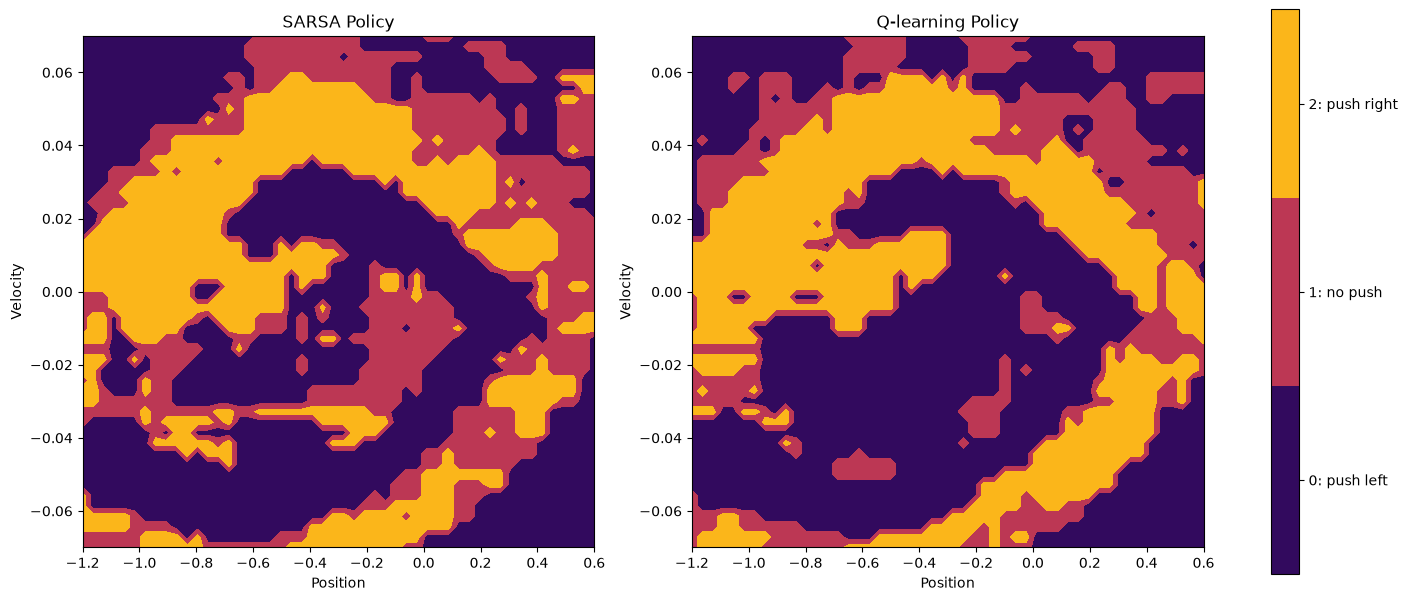

In [13]:
import matplotlib.pyplot as plt
import numpy as np

position_bounds = [-1.2, 0.6]
velocity_bounds = [-0.07, 0.07]
x = np.linspace(position_bounds[0], position_bounds[1], 50)
xp = np.linspace(velocity_bounds[0], velocity_bounds[1], 50)
X, Y = np.meshgrid(x, xp)

def q0(x, xp, w):
    return np.argmax([
        np.sum(w[get_features([x, xp], action)]) 
        for action in [0,1,2]
    ])
q0_sarsa = np.vectorize(lambda x, xp: q0(x, xp, w_sarsa))
q0_q     = np.vectorize(lambda x, xp: q0(x, xp, w_Q))

Z_sarsa = q0_sarsa(X, Y)
Z_q     = q0_q(X, Y)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')

# --- SARSA plot ---
cp1 = axes[0].contourf(X, Y, Z_sarsa, levels=[-0.5, 0.5, 1.5, 2.5], cmap='inferno')
axes[0].set_title('SARSA Policy')
axes[0].set_xlabel('Position')
axes[0].set_ylabel('Velocity')

# --- Q-learning plot ---
cp2 = axes[1].contourf(X, Y, Z_q, levels=[-0.5, 0.5, 1.5, 2.5], cmap='inferno')
axes[1].set_title('Q-learning Policy')
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Velocity')

# --- same aspect ratio ---
x_range = position_bounds[1] - position_bounds[0]
y_range = velocity_bounds[1] - velocity_bounds[0]
for ax in axes:
    ax.set_aspect(x_range / y_range)

# --- one shared colorbar (optional but cleaner) ---
cbar = fig.colorbar(cp1, ax=axes.ravel().tolist(), ticks=[0, 1, 2])
cbar.ax.set_yticklabels(['0: push left', '1: no push', '2: push right'])
plt.show()

In [14]:
! python -m jupyter nbconvert 10_function_approximation_for_control_hw.ipynb --to webpdf

[NbConvertApp] Converting notebook 10_function_approximation_for_control_hw.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Building PDF
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 167185 bytes to 10_function_approximation_for_control_hw.pdf
